#### Import libraries

In [2]:
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt
import sys
# Append root folder
sys.path.append('../')
import data_processing.utils.utils as utils


#### Load the data

In [3]:
train_df = pd.read_excel('../data/raw/train.xlsx')
test_df = pd.read_excel('../data/raw/test.xlsx')

#### Check amount of data

In [54]:
# Check length of train and test data
print('Train data length:', len(train_df))
print('Test data length:', len(test_df))

# Calculate percentage of train and test data
print('Train data percentage:', len(train_df) / (len(train_df) + len(test_df)))
print('Test data percentage:', len(test_df) / (len(train_df) + len(test_df)))

Train data length: 62699
Test data length: 17103
Train data percentage: 0.7856820631061878
Test data percentage: 0.21431793689381218


#### Check data schema

In [55]:
train_df.dtypes

driver_birth_date                           datetime64[ns]
driver_driving_license_ym                           object
driver_other_vehicles                               object
driver_insured_years                                object
occasional_driver_birth_date                datetime64[ns]
occasional_driver_license_attainment_age           float64
policyholder_age                                   float64
policyholder_license_attainment_age                float64
vehicle_acquisition_state                           object
vehicle_buy_ym                                      object
vehicle_registration_ym                             object
vehicle_engine_power                                 int64
vehicle_number_of_doors                              int64
vehicle_use                                         object
driver_claims_last_1_year                            int64
driver_claims_from_year_1_to_2                       int64
driver_claims_from_year_2_to_3                       int

`vehicle_registration_ym`, `vehicle_buy_ym` and `driver_driving_license_ym` need to be casted to datetime

In [4]:
train_df = utils.clean_column_types(train_df)

In [57]:
# Show all columns without truncating
pd.set_option('display.max_columns', None)
# Show first 5 rows of train data
train_df.head()

,driver_birth_date,driver_driving_license_ym,driver_other_vehicles,driver_insured_years,occasional_driver_birth_date,occasional_driver_license_attainment_age,policyholder_age,policyholder_license_attainment_age,vehicle_acquisition_state,vehicle_buy_ym,vehicle_registration_ym,vehicle_engine_power,vehicle_number_of_doors,vehicle_use,driver_claims_last_1_year,driver_claims_from_year_1_to_2,driver_claims_from_year_2_to_3,driver_claims_from_year_3_to_4,driver_claims_from_year_4_to_5,timestamp,competitor_lowest_price,number_of_competitors,quote_id
0,1950-05-12,1969-04-01,NaN,MORE_THAN_TEN,NaT,NaN,NaN,NaN,OWNED,2006-03-01,2006-03-01,98,4,HABITUAL,0,0,0,0,0,2023-05-01 00:04:22,196.26,10,51d5ba7e8044c72ff5f981b46c09ae37ba55551c50f4ac...
1,1986-08-09,2011-05-01,BIKE,ONE,NaT,NaN,NaN,NaN,OWNED,2020-06-01,2004-09-01,170,4,HABITUAL,0,0,0,0,0,2023-05-01 00:08:44,220.20,9,cae1d02522b96ef3ed7f9785ee283da7888b84692b56b4...
2,1988-03-24,2006-03-01,NaN,FOUR,1986-04-20,18.0,NaN,NaN,RECENT_SECOND_HAND_FROM_PRIVATE,2023-05-01,2008-03-01,102,5,OCCASIONAL,0,0,0,0,0,2023-05-01 00:17:10,234.11,9,6215cd4d59e461c525685278a8c7b7ed0d2650693e1eef...
3,1972-07-20,1994-07-01,CAR,SIX,1967-01-27,18.0,NaN,NaN,OWNED,2022-05-01,2021-11-01,100,5,OCCASIONAL,0,0,0,0,0,2023-05-01 00:19:47,145.98,14,f072220d72571df3560f77c74d7f691c73ae913095a3c2...
4,1975-02-16,2007-04-01,NaN,ONE,NaT,NaN,NaN,NaN,OWNED,2017-07-01,2003-01-01,105,5,HABITUAL,1,0,0,0,0,2023-05-01 00:23:57,245.90,9,daecd73a0c6ce56303f2f117b4c9d5f2b788fef68f7234...


In [58]:
# Check difference between train and test data columns
print('\nColumns in train data but not in test data:\n', set(train_df.columns) - set(test_df.columns))


Columns in train data but not in test data:
 {'number_of_competitors', 'competitor_lowest_price'}


#### Data summary and descriptive statistics

In [22]:
# Describe numerical features in train data
numerical_features = train_df.select_dtypes(include=['int64', 'float64']).columns
train_df[numerical_features].describe()

,driver_insured_years,vehicle_engine_power,vehicle_number_of_doors,driver_claims_last_1_year,driver_claims_from_year_1_to_2,driver_claims_from_year_2_to_3,driver_claims_from_year_3_to_4,driver_claims_from_year_4_to_5,competitor_lowest_price,number_of_competitors,driver_age,years_with_license,years_since_bought,years_since_registered,driver_claims
count,62699.000000,62699.000000,62699.000000,62699.000000,62699.000000,62699.000000,62699.000000,62699.000000,62699.000000,62699.000000,62699.000000,62699.000000,62699.000000,62699.000000,62699.000000
mean,4.053542,120.642690,4.613327,0.020016,0.011723,0.011707,0.005790,0.004003,247.628708,9.646884,45.827764,24.046428,6.634332,11.793777,0.033222
std,3.464956,42.753791,0.768983,0.144981,0.113126,0.112634,0.080757,0.066587,86.765620,3.083937,11.643594,11.702791,6.129611,7.083996,0.189260
min,0.000000,1.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,132.150000,3.000000,20.000000,1.000000,1.000000,1.000000,0.000000
25%,1.000000,90.000000,5.000000,0.000000,0.000000,0.000000,0.000000,0.000000,179.380000,7.000000,37.000000,15.000000,1.000000,6.000000,0.000000
50%,3.000000,112.000000,5.000000,0.000000,0.000000,0.000000,0.000000,0.000000,219.510000,10.000000,45.000000,23.000000,5.000000,11.000000,0.000000
75%,6.000000,140.000000,5.000000,0.000000,0.000000,0.000000,0.000000,0.000000,295.105000,12.000000,54.000000,32.000000,10.000000,18.000000,0.000000
max,11.000000,507.000000,6.000000,3.000000,3.000000,3.000000,4.000000,3.000000,499.970000,19.000000,94.000000,65.000000,36.000000,54.000000,4.000000


There are no visible outliers in the numerical features

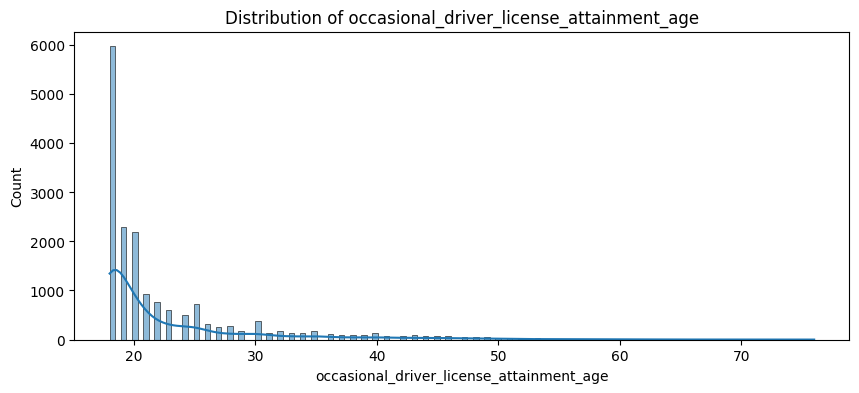

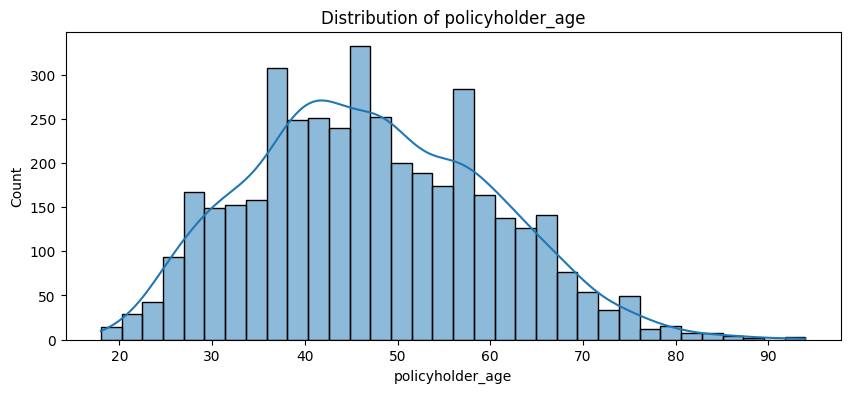

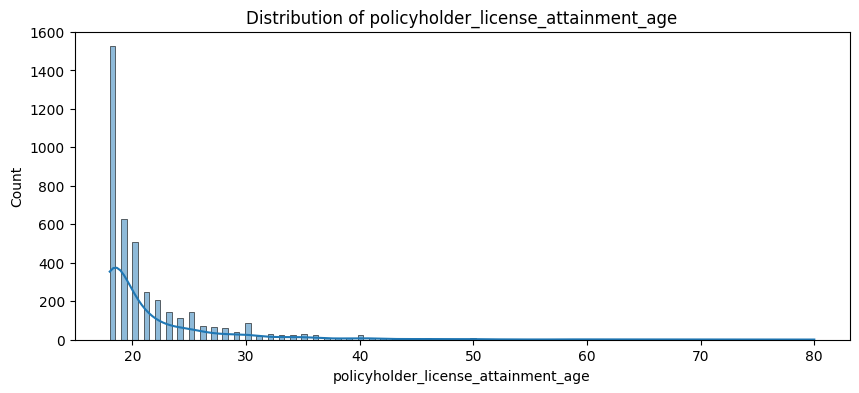

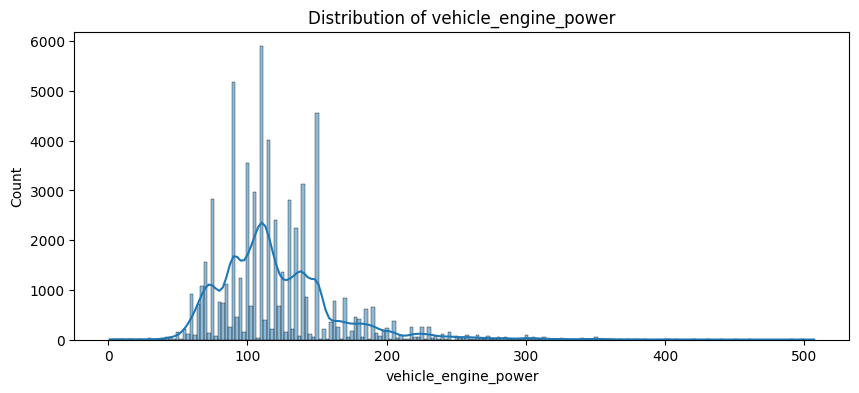

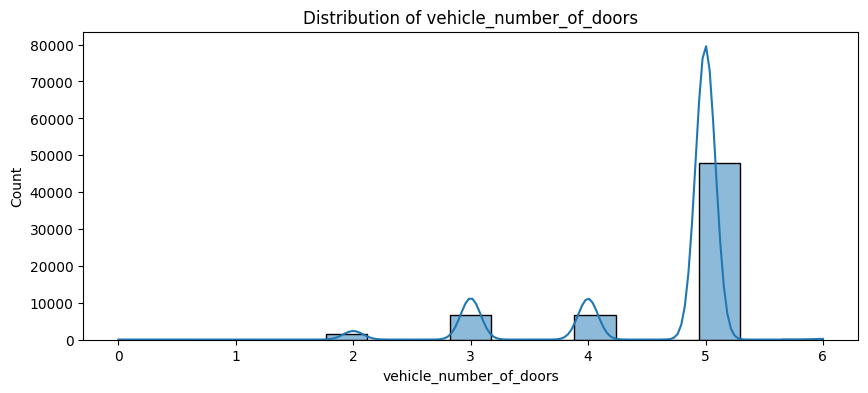

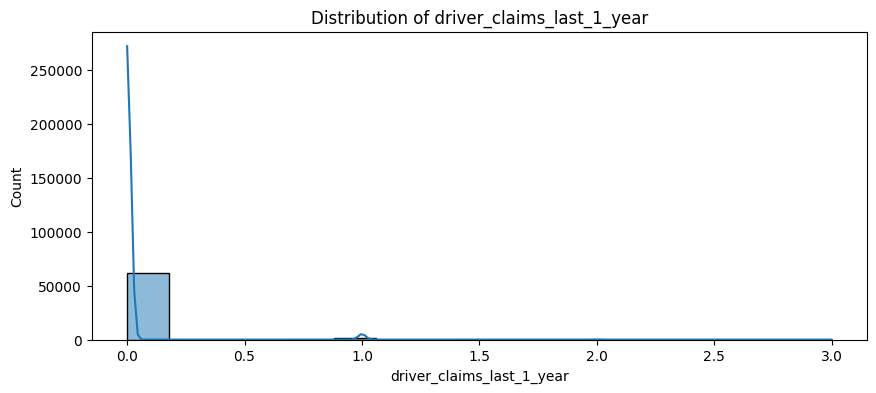

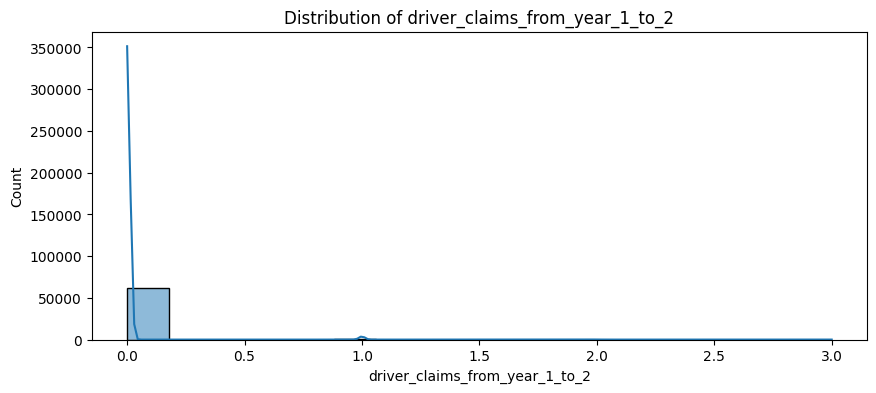

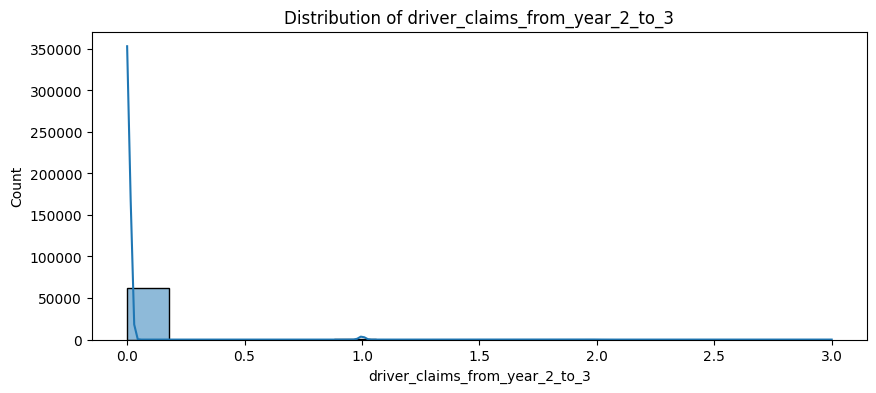

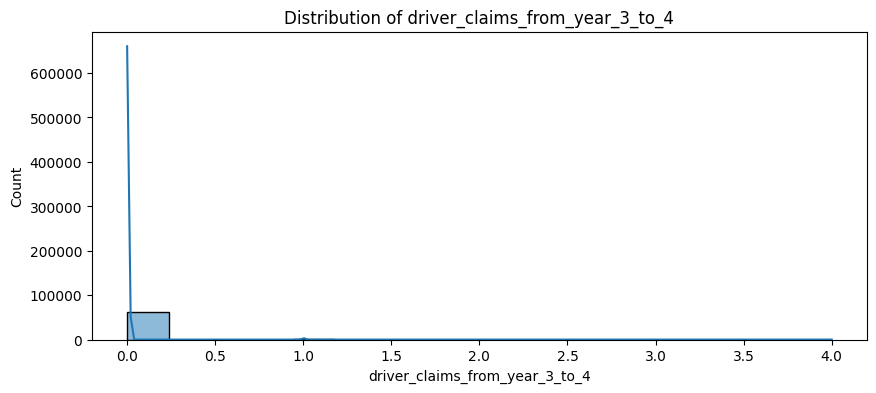

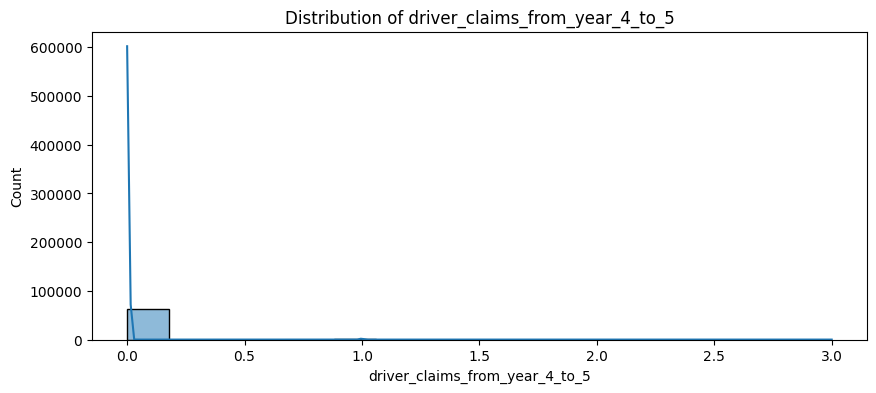

In [63]:
# Histograms for numerical features, competitor_lowest_price and number of competitors
for feature in numerical_features[:-2]:
    plt.figure(figsize=(10, 4))
    sns.histplot(train_df[feature], kde=True)
    plt.title(f'Distribution of {feature}')
    plt.show()

#### Check for missing values

In [64]:
# Check for missing values in train data
missing_values = train_df.isnull().sum()
# Calculate percentage of missing values
(missing_values[missing_values > 0] / len(train_df))*100

driver_other_vehicles                       47.541428
driver_insured_years                        11.373387
occasional_driver_birth_date                72.092059
occasional_driver_license_attainment_age    72.092059
policyholder_age                            93.435302
policyholder_license_attainment_age         93.435302
dtype: float64

#### Treating missing values

`driver_other_vehicles` missing values can be replaced with the categorical value `'NONE'`

`drived_insured_years` missing values can be replaced with the categorical value `'ZERO'`

Due to the high amount of missing rows in occasional driver and policy holder columns, this columns can be dropped and instead generate new features with the information they have. These could be `has_occasional_driver` and `has_other_policyholder`

In [5]:
train_df = utils.treat_missing_values(train_df)

#### Analyze the categorical values

In [15]:
# Bar plots for categorical features
categorical_features = train_df.select_dtypes(include=['object']).columns
# Exclude quote_id column
categorical_features = categorical_features[:-1]

# Show unique values percentage for each categorical feature
for feature in categorical_features:
    print('Values percentage for:')
    print(train_df[feature].value_counts(normalize=True)*100, '\n')


Values percentage for:
driver_other_vehicles
NONE     47.541428
CAR      28.636820
OTHER    14.242651
BIKE      9.579100
Name: proportion, dtype: float64 

Values percentage for:
driver_insured_years
ONE              16.477137
TWO              14.481890
THREE            12.898132
MORE_THAN_TEN    12.043254
ZERO             11.373387
FIVE             10.102234
FOUR              9.261711
SIX               4.411554
SEVEN             2.883619
EIGHT             2.537521
TEN               2.464154
NINE              1.065408
Name: proportion, dtype: float64 

Values percentage for:
vehicle_acquisition_state
OWNED                                 71.895884
RECENT_SECOND_HAND_FROM_PRIVATE       11.406880
RECENT_SECOND_HAND_FROM_CAR_DEALER     8.791209
RECENT_FIRST_HAND                      5.666757
BUYING_SECOND_HAND_FROM_CAR_DEALER     0.872422
BUYING_SECOND_HAND_FROM_PRIVATE        0.703361
BUYING_FIRST_HAND                      0.663487
Name: proportion, dtype: float64 

Values percentage for

#### Encoding categorical values

`driver_other_vehicles` should be encoded with one-hot encoding

`driver_insured_years` should be encoded with an ordinal encoding

`vehicle_acquisition_state` should be encoded with one-hot encoding

`vehicle_use` could be dropped and tranformed into `professional` (boolean) and `habitual` (boolean)

In [16]:
train_df = utils.encode_categorical_features(train_df)

#### Feature generation

`driver_age` can be generated, dropping driver `birth date`

`years_with_license` can be generated, dropping `driver_driving_license_ym`

`driver_has_other_vehicles` can be generated from `driver_other_vehicles`

`driver_has_been_insured` can be generated from `driver_insured years`

`years_since_bought` can be generated, dropping `vehicle_buy_ym`

`years_since_registered` can be generated, dropping `vehicle_registration_ym`

`driver_claims` can be generated from driver claims features





In [17]:
train_df = utils.generate_features(train_df)

#### New features analysis

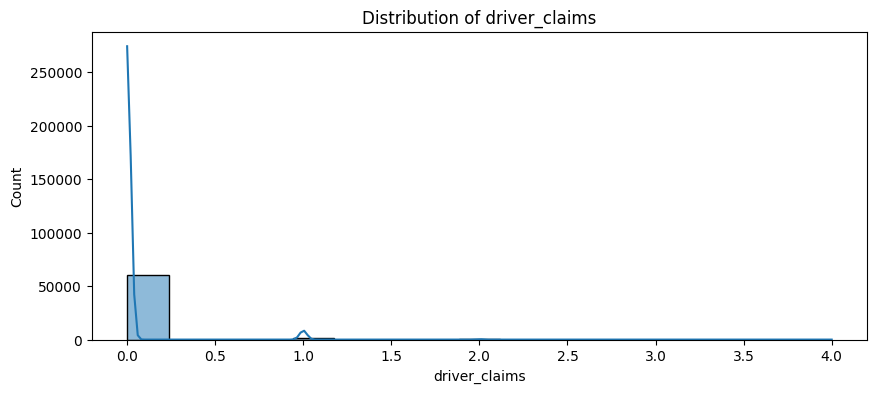

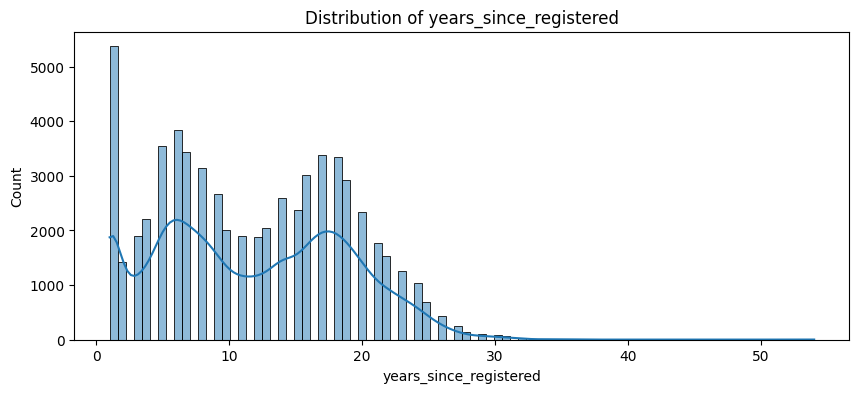

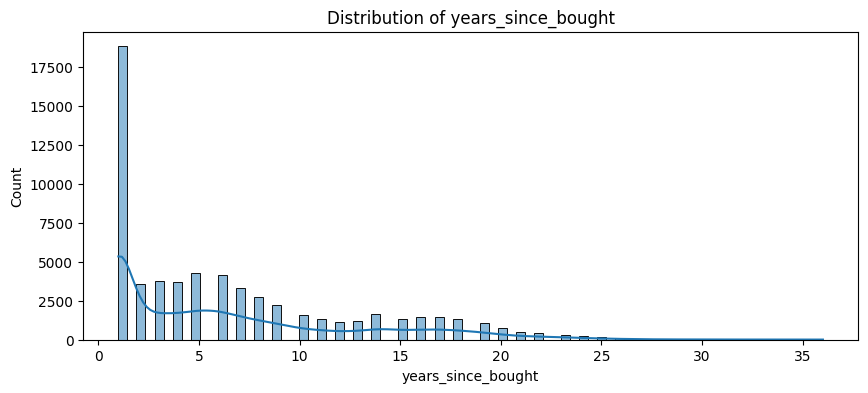

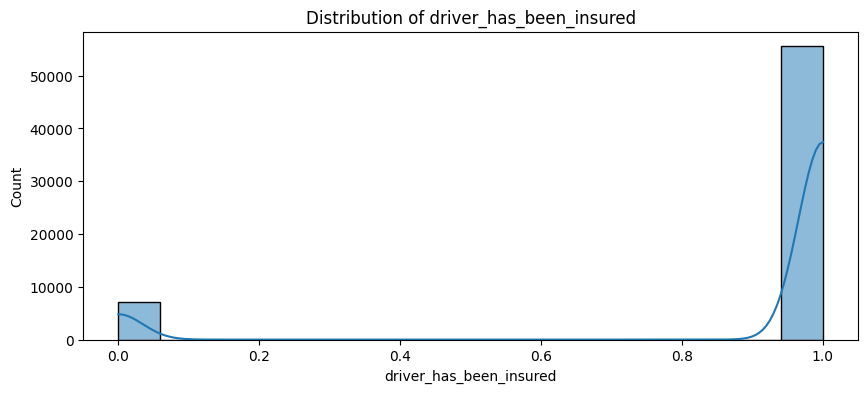

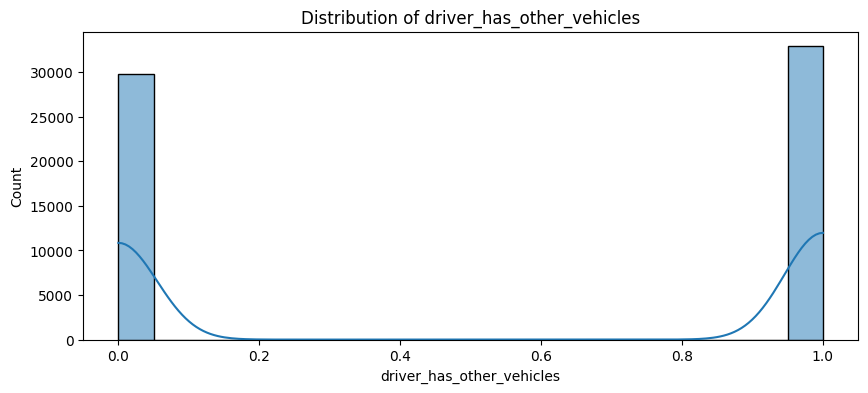

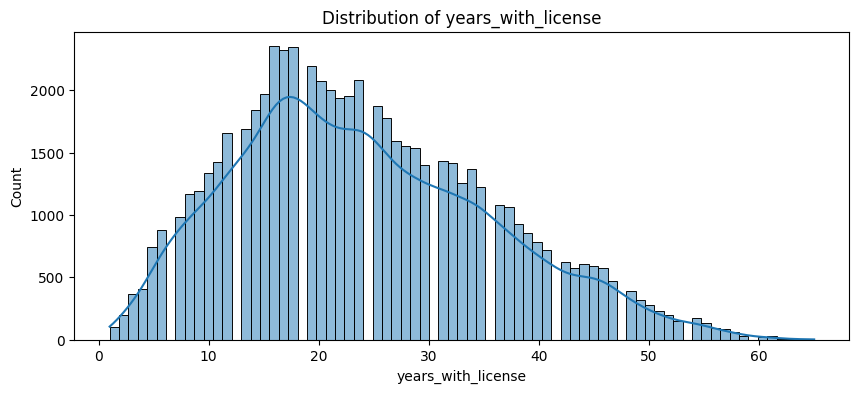

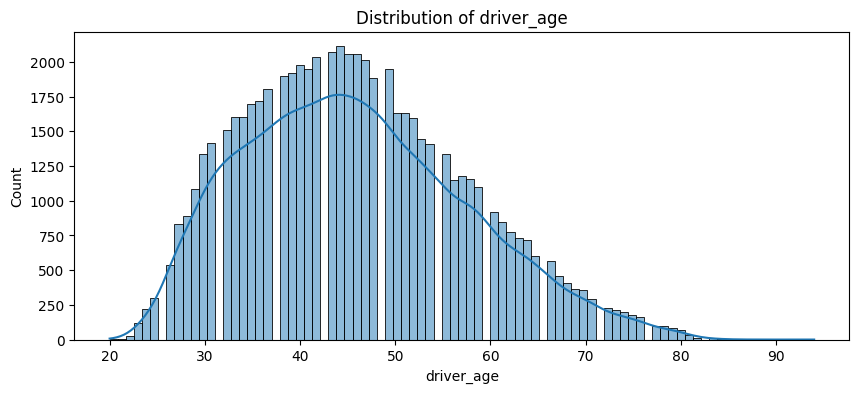

In [34]:
# Histograms for numerical features, competitor_lowest_price and number of competitors
new_generated_features = ['driver_claims', 'years_since_registered', 'years_since_bought', 'driver_has_been_insured', 'driver_has_other_vehicles', 'years_with_license', 'driver_age']

for feature in new_generated_features:
    plt.figure(figsize=(10, 4))
    sns.histplot(train_df[feature], kde=True)
    plt.title(f'Distribution of {feature}')
    plt.show()

#### Target feature analysis

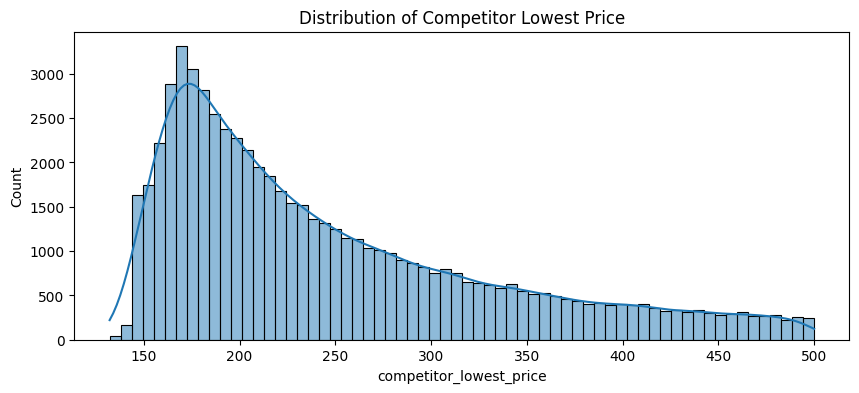

In [18]:
# Distribution of the target variable
plt.figure(figsize=(10, 4))
sns.histplot(train_df['competitor_lowest_price'], kde=True)
plt.title('Distribution of Competitor Lowest Price')
plt.show()

In [27]:
# Calculate correlation between numerical features and target variable. Sort in descending absolute order
train_df[numerical_features].corr()['competitor_lowest_price'].sort_values(key=lambda x: abs(x), ascending=False)

competitor_lowest_price           1.000000
number_of_competitors            -0.610190
driver_insured_years             -0.351361
years_with_license               -0.252182
years_since_bought               -0.198842
driver_age                       -0.190827
years_since_registered            0.099455
driver_claims                     0.096911
driver_claims_last_1_year         0.087547
driver_claims_from_year_1_to_2    0.068552
driver_claims_from_year_2_to_3    0.055367
vehicle_engine_power              0.053363
vehicle_number_of_doors          -0.043392
driver_claims_from_year_3_to_4    0.040076
driver_claims_from_year_4_to_5    0.016726
Name: competitor_lowest_price, dtype: float64

It's interesting to notice that `number_of_competitors` has a great correlation with the target variable. As it is not present in the test data, it could be used by training a model to predict it, and then use it as a feature in the `competitor_lowest_price` model. As an initial approach, it won't be used for the model.

#### Feature Selection

In [32]:
# print columns
for col in train_df.columns:
    print(col)

driver_insured_years
vehicle_engine_power
vehicle_number_of_doors
driver_claims_last_1_year
driver_claims_from_year_1_to_2
driver_claims_from_year_2_to_3
driver_claims_from_year_3_to_4
driver_claims_from_year_4_to_5
timestamp
competitor_lowest_price
number_of_competitors
quote_id
has_occasional_driver
has_other_policyholder
driver_other_vehicles_BIKE
driver_other_vehicles_CAR
driver_other_vehicles_NONE
driver_other_vehicles_OTHER
vehicle_acquisition_state_BUYING_FIRST_HAND
vehicle_acquisition_state_BUYING_SECOND_HAND_FROM_CAR_DEALER
vehicle_acquisition_state_BUYING_SECOND_HAND_FROM_PRIVATE
vehicle_acquisition_state_OWNED
vehicle_acquisition_state_RECENT_FIRST_HAND
vehicle_acquisition_state_RECENT_SECOND_HAND_FROM_CAR_DEALER
vehicle_acquisition_state_RECENT_SECOND_HAND_FROM_PRIVATE
professional_vehicle_use
habitual_vehicle_use
driver_age
years_with_license
driver_has_other_vehicles
driver_has_been_insured
years_since_bought
years_since_registered
driver_claims


In order to train models, we will initially remove `quote_id`, `timestamp` and `number_of_competitors`. The first two are discarded as they are unique values, and won't add value to the data. `timestamp` is an interesting feature to consider if we abroad this problem as a time-series one, but it won't enter in the scope of this project.

After some experimentation, further feature selection can be done taking a look at feature importance and correlations.